# 1.Introduction

This notebook demonstrates fine-tuning the Gemma model to create **ArGemma**, a specialized version tailored for Arabic. 

### Objectives:
- **Fostering Cross-Language Collaboration**  
  - Improve Gemma's ability in **Arabic-English translation**, bridging gaps for tasks requiring bilingual proficiency.
- **Empowering Creative Applications**  
  - Adapt Gemma for **storytelling**, **dialogue generation**, **letter generation** and **summarization**, making it suitable for generating engaging narratives, concise content, and interactive dialogues in Arabic.
- **Building Bridges Between Arabic Variants**  
  - Enhance the understanding between **Classical Arabic** (Used in the Quran, poetry, and folklore) and **Modern Standard Arabic** (used in news and education).  

ArGemma is a step toward enriching the Arabic NLP landscape by uniting tradition and modernity while pushing the boundaries of AI applications.

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Abstract: </strong>This work focuses on fine-tuning the Gemma 2 model for Arabic tasks, emphasizing data curation, fine-tuning methodologies, and evaluation techniques. The dataset was built using diverse sources, including Arabic-English sentence pairs, short stories, dialogues, letters, texts with their summaries, the Quran with Tafsir, Arabic poetry with explanations, proverbs with explanations, and modern Arabic lexicons. Both human-crafted and AI-generated paired instruction-input and response-output texts were used. For fine-tuning, Supervised Fine-Tuning with LoRA was applied to tasks like translation, summarization, storytelling, and dialogue generation. Additionally, a Hybrid Approach combining Supervised Fine-Tuning with LoRA, Retrieval-Augmented Generation (RAG), and Few-Shot Prompting was employed for bridging Classical and Modern Arabic tasks. Evaluation combined quantitative metrics and qualitative assessments to validate fluency, coherence, and task-specific effectiveness. This approach demonstrates Gemma 2's potential for Arabic language processing and cultural inclusivity.
    </p>
</div>

In [1]:
from IPython.display import HTML
from base64 import b64encode

def play(filename):
    html = ''
    video = open(filename,'rb').read()
    src = 'data:video/mp4;base64,' + b64encode(video).decode()
    html += '<video width=800 controls autoplay><source src="%s" type="video/mp4"></video>' % src 
    return HTML(html)

play('/kaggle/input/argemma/other/default/11/ArGemma.mp4')

# 2.Notebook Summary  

- **Understanding Gemma**:  
  This section provides an overview of the Gemma language model, highlighting its capabilities, and versatility. 
- **Environment Setup**:  
  This section covers the installation of packages, importing libraries, and configuring model parallelism for distributed training. The Gemma model is loaded, and the language model is optimized with LoRA settings for fine-tuning across multiple TPUs. Additionally, the pre-trained semantic search model is loaded.
- **Data Sources**:  
  Here, the dataset creation and curation process for various tasks, including translation, storytelling, dialogue generation, summarization, and bridging Classical and Modern Standard Arabic, is discussed. Different datasets are used for each task to ensure comprehensive model training. A Knowledge Base for RAG is prepared to enhance retrieval-augmented generation.

- **Fine-Tuning Methods**:  
  This section outlines the fine-tuning process, including Supervised Fine-Tuning with LoRA and the Hybrid Approach combining Supervised Fine-Tuning with LoRA, Retrieval-Augmented Generation (RAG), and Few-Shot Prompting. The training procedures, hyperparameter settings, and optimizations used to enhance the model’s performance across various tasks are discussed.

- **Evaluation**:  
  This section presents the evaluation of ArGemma's performance using both quantitative methods like BLEU and ROUGE, as well as qualitative methods. You will see how custom functions are created to use evaluation metrics like ROUGE with Arabic. Additionally, native speakers and language experts are involved in evaluating the model's performance for a more accurate qualitative assessment.

- **Let's try ArGemma**:  
  In this section, you'll find a demo for using ArGemma. If you'd like, you can first set up the environment by following the instructions in the Environment Setup section. Once that's done, you can proceed to this section to use ArGemma, just like you saw in the video.

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note: </strong>To make the code easier to read, I have organized it into functions. The function definitions are hidden, and only the function calls are displayed. If you want to view the structure of any function, you can simply press <strong><em>Show Hidden Code</em></strong>
    </p>
</div>

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note: </strong>Different variants of LoRA weights will be found in the model, as previously mentioned, due to limited computing resources. Each variant is labeled with letters indicating the task, such as:
<strong>tr:</strong> Translation,
<strong>sm:</strong> Summarization,
<strong>sd:</strong> Storytelling and Dialogue Generation,
<strong>br:</strong> Bridging Classical and Modern Arabic tasks
    </p>
</div>


# 3.Understanding Gemma

- **Introduction to Gemma**:  
  Gemma is a family of lightweight, state-of-the-art open models built from the same research and technology used to create the Gemini models. Developed by Google DeepMind and other teams across Google, the name "Gemma" is derived from the Latin word *gemma*, meaning "precious stone. 
- **Pretrained and Instruction Tuned Models**: Gemma models are available in two versions, allowing flexibility for various applications:
  * **Instruction Tuned (IT):**  
  These models are fine-tuned with human language interactions, making them capable of responding to conversational inputs, similar to a chatbot. They are ideal for applications where human-like communication is required.
  * **Pretrained (PT):**  
  These models are not specialized for any specific tasks or instructions beyond the core data training. They require further tuning to perform targeted tasks effectively. Note that deploying PT models in applications without tuning is not recommended.

- **Gemma models list**: Below is a summary of the Gemma model variants, their parameter sizes, and intended use cases

| Parameter Size | Input        | Output | Foundation | Variants                                    | Intended Platforms                     |
|----------------|--------------|--------|------------|---------------------------------------------|----------------------------------------|
| 2B             | Text         | Text   | Gemma 2    | Gemma 2 (base)                              | Mobile devices and laptops             |
| 2B             | Text         | Text   | Gemma 1    | Gemma (base), CodeGemma, RecurrentGemma     | Mobile devices and laptops             |
| 3B             | Text, Images | Text   | Gemma 2    | PaliGemma 2                                 | Desktop computers and small servers    |
| 7B             | Text         | Text   | Gemma 1    | Gemma (base), CodeGemma                     | Desktop computers and small servers    |
| 9B             | Text         | Text   | Gemma 2    | Gemma 2 (base)                              | Higher-end desktop computers and servers |
| 9B             | Text         | Text   | Gemma 1    | RecurrentGemma                              | Higher-end desktop computers and servers |
| 10B            | Text, Images | Text   | Gemma 2    | PaliGemma 2                                 | Higher-end desktop computers and servers |
| 27B            | Text         | Text   | Gemma 2    | Gemma 2 (base)                              | Large servers or server clusters       |
| 28B            | Text, Images | Text   | Gemma 2    | PaliGemma 2                                 | Large servers or server clusters       |


# 4.Environment Setup

In [2]:
# Install packages
!pip install -q -U keras-nlp tensorflow-text
!pip install -q -U tensorflow-cpu
!pip install nltk
!pip install datasets
!pip install sentence_transformers
!pip install --upgrade ipywidgets

import os
os.environ["KERAS_BACKEND"] = "jax"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "1.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.16.0 requires tensorflow<2.17,>=2.16, but you have tensorflow 2.18.0 which is incompatible.

[notice] A new release of pip is available: 23.0.1 -> 25.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 23.0.1 -> 25.0.1
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 16.5 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 23.0.1 -> 25.0.1
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 8.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 39.4 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 22.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import keras
import keras_nlp
import torch
from datasets import load_dataset
from sklearn.utils import shuffle
from sentence_transformers import SentenceTransformer, util
from nltk.translate.bleu_score import sentence_bleu
from collections import Counter
from ipywidgets import Button, Layout, Box, VBox, HBox, Textarea, Label , Dropdown,HTML
import ipywidgets as widgets

/usr/local/lib/python3.10/site-packages/torch_xla/__init__.py:202: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(
W0210 01:47:33.138000 133214769055424 torch/_inductor/compile_worker/subproc_pool.py:126] SubprocPool unclean exit


In [4]:
def create_device_mesh(shape, dimension_names, devices):
    """
    Create a device mesh for distributing weights across devices.

    Args:
        shape (tuple): Shape of the device mesh (e.g., (1, 8)).
        dimension_names (list): Names for the mesh dimensions (e.g., ["batch", "model"]).
        devices (list): List of devices to include in the mesh.

    Returns:
        keras.distribution.DeviceMesh: Configured device mesh.
    """
    return keras.distribution.DeviceMesh(shape, dimension_names, devices=devices)

def create_layout_map(device_mesh, model_dim):
    """
    Create a layout map for sharding weights across devices.

    Args:
        device_mesh (keras.distribution.DeviceMesh): The device mesh.
        model_dim (str): Dimension name for the model parallelism.

    Returns:
        keras.distribution.LayoutMap: Configured layout map.
    """
    layout_map = keras.distribution.LayoutMap(device_mesh)

    # Shard token embeddings across devices
    layout_map["token_embedding/embeddings"] = (model_dim, None)

    # Shard query, key, and value matrices in attention layers
    layout_map["decoder_block.*attention.*(query|key|value)/kernel"] = (model_dim, None, None)

    # Shard attention output kernels
    layout_map["decoder_block.*attention_output/kernel"] = (model_dim, None, None)

    # Shard gating kernels in feed-forward layers
    layout_map["decoder_block.*ffw_gating.*/kernel"] = (None, model_dim)

    # Shard linear kernels in feed-forward layers
    layout_map["decoder_block.*ffw_linear/kernel"] = (model_dim, None)

    return layout_map

def configure_model_parallel(shape, dimension_names, model_dim):
    """
    Configure model parallelism for distributed training.

    Args:
        shape (tuple): Shape of the device mesh (e.g., (1, 8)).
        dimension_names (list): Names for the mesh dimensions (e.g., ["batch", "model"]).
        model_dim (str): Dimension name for the model parallelism.
    """
    # Create device mesh
    devices = keras.distribution.list_devices()
    device_mesh = create_device_mesh(shape, dimension_names, devices)

    # Create layout map
    layout_map = create_layout_map(device_mesh, model_dim)

    # Configure model parallel distribution
    model_parallel = keras.distribution.ModelParallel(
        layout_map=layout_map,
        batch_dim_name="batch",
    )

    keras.distribution.set_distribution(model_parallel)

In [5]:
# Configure model parallelism 
# Create a device mesh with (1, 8) shape so that the weights are sharded across all 8 TPUs.
configure_model_parallel(shape=(1,8), dimension_names=["batch", "model"], model_dim="model")

E0000 00:00:1739150866.234646      41 common_lib.cc:798] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: ===
learning/45eac/tfrc/runtime/common_lib.cc:479
E0210 01:27:46.265831997      41 oauth2_credentials.cc:238]            oauth_fetch: UNKNOWN:C-ares status is not ARES_SUCCESS qtype=A name=metadata.google.internal. is_balancer=0: Domain name not found {grpc_status:2, created_time:"2025-02-10T01:27:46.265814438+00:00"}


In [6]:
# Load Gemma model (2B or 9B)
# Do not apply model parallelism for the 2B model (in the above cell)
model_versions = ["gemma2_instruct_2b_en","gemma2_instruct_9b_en"]
gemma_lm = keras_nlp.models.GemmaCausalLM.from_preset(model_versions[1])

normalizer.cc(51) LOG(INFO) precompiled_charsmap is empty. use identity normalization.


In [7]:
def configure_gemma_lm(rank, length, learning_rate, weight_decay, var_names):
    """
    Configure the Gemma language model with LoRA and optimizer settings.

    Args:
        rank (int): Rank for LoRA (Low-Rank Adaptation) in the model.
        length (int): Sequence length for input processing.
        learning_rate (float): Learning rate for the AdamW optimizer.
        weight_decay (float): Weight decay for the AdamW optimizer.
        var_names (list): List of variable (["bias", "scale"]) to exclude from weight decay.
    """
    # Enable LoRA for the model and set the LoRA rank
    gemma_lm.backbone.enable_lora(rank=rank)
    gemma_lm.summary()

    # Limit the input sequence length
    gemma_lm.preprocessor.sequence_length = length

    # Create the AdamW optimizer
    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate,
        weight_decay=weight_decay,
    )

    # Exclude specified variables from weight decay
    optimizer.exclude_from_weight_decay(var_names=var_names)

    # Compile the model with SparseCategoricalCrossentropy loss and SparseCategoricalAccuracy metric
    gemma_lm.compile(
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=optimizer,
        weighted_metrics=[keras.metrics.SparseCategoricalAccuracy()],
    )

In [8]:
# Configure the Gemma language model with LoRA and optimizer settings for fine-tuning.
configure_gemma_lm(rank=8, length=512, learning_rate=1e-4, weight_decay=0.01, var_names=["bias", "scale"])

Preprocessor: "gemma_causal_lm_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gemma_tokenizer (GemmaTokenizer)                              │                      Vocab size: 256,000 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "gemma_causal_lm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gemma_backbone                │ (None, None, 3584)        │   9,270,779,392 │ padding_mask[0][0],        │
│ (GemmaBackbone)               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_embedding               │ (None, None, 256000)      │     917,504,000 │ gemma_backbone[0][0]       │
│ (ReversibleEmbedding)         │                           │                 │                            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 9,270,779,392 (34.54 GB)

 Trainable params: 29,073,408 (110.91 MB)

 Non-trainable params: 9,241,705,984 (34.43 GB)

In [ ]:
# Load LoRA weights to apply fine-tuned weights
#gemma_lm.backbone.load_lora_weights("/kaggle/input/argemma/other/default/11/ArGemma_9b_tr.lora.h5")
# save only the lora weights
#gemma_lm.backbone.save_lora_weights("ArGemma_9b_sd.lora.h5")

In [9]:
# bi_encoder and semantic_search_model will be used in different cells
# Model Initialization
model_name = 'Omartificial-Intelligence-Space/Arabert-all-nli-triplet-Matryoshka'
bi_encoder = SentenceTransformer(model_name)

# Load the pre-trained semantic search model 
semantic_search_model_path = '/kaggle/input/argemma/other/default/11/semantic_search_model.pt'
semantic_search_model = torch.load(semantic_search_model_path, map_location=torch.device('cpu'))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/205 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/311k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/637 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/761k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.78M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

/tmp/ipykernel_41/1281107756.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  semantic_search_model = torch.load(semantic_search_model_path, map_location=torch.device('cp

# 5.Data Sources 📚  

The datasets used for fine-tuning ArGemma include diverse and carefully curated sources to ensure comprehensive coverage of Arabic language tasks:

- **The Arabic-English Sentence Bank 25k**:  A bilingual dataset with 25,000 diverse sentences in Arabic and English, created with AI assistance to support various language processing tasks. It includes sentences categorized into distinct types and was used in this project to improve the model for translation between Arabic and English. 
___
- **InstAr-500k**:  This dataset consists of paired instruction-input and answer-output texts, covering various tasks such as classification, summarization, paraphrasing, and more. It includes both human-crafted and synthetic data sources. The human-crafted data was sourced from platforms like Hugging Face, GitHub, and Kaggle, and transformed into instruction-response pairs. The synthetic data was generated using high-quality raw text from the 101 Billion Arabic Words Dataset, with task-specific prompts by the Command R+ model. In this project, the dataset was used to enhance model performance for summarization. See resources **[4]**
- **ArabSummaries**:
  A dataset containing 7,000 Arabic texts across seven domains—Culture, Medical, Politics, Religion, Sports, and Technology. Each text is paired with an AI-generated summary. The dataset is based on the original [SANAD](https://www.kaggle.com/datasets/haithemhermessi/sanad-dataset?select=Finance) dataset and is intended for Arabic text summarization research, model training, and evaluation.
___
- **Arabic Short Stories Collection 5k**: A diverse dataset containing 5,000 Arabic short stories, sourced from both human-authored and AI-generated content. The stories span various genres, including Religion, Imaginary, Inspirational, Children's Stories, Heroic, and more. This dataset serves as a valuable resource for Arabic storytelling and content generation.
- **Arabic Dialogues 5k**: A collection of 5,000 short Arabic dialogues, generated by AI, covering a wide range of topics such as household conversations, school discussions, market interactions, conversations between friends and family members, and various topics like science, society, technology, and culture. This dataset is ideal for dialogue generation and content creation tasks, providing diverse and realistic examples of daily conversations in Arabic.
- **Arabic Letters**:  A dataset of 500 AI-generated letters covering various topics such as messages to customers, companies, friends, as well as requests, responses, and more. This collection is designed for Arabic message generation tasks, providing diverse and realistic examples for NLP and content creation applications.
  ___
- **Quran with Tafsir**: A dataset containing Quranic verses paired with their corresponding Tafsir (exegesis). The Tafsir is sourced from Al-Mukhtasar fi Tafsir al-Quran al-Karim, a modern and concise Tafsir written in 2010 by a group of scholars. This Tafsir is known for its clarity and simplicity, making it accessible for study and understanding. This dataset is valuable for bridging the gap between Classical Arabic and Modern Standard Arabic, especially in the context of religious texts, to enhance models designed for both. 
- **Arabic Proverbs Collection**: A dataset containing proverbs in Classical Arabic, Colloquial Arabic, and Popular Arabic, each paired with explanations. It includes Classical Arabic proverbs from Majma' al-Amthal by Abi al-Fadl al-Maydani (1124), Colloquial Arabic proverbs from Colloquial Proverbs by Ahmad Taymour Pasha (1949), and AI-generated popular proverbs. This dataset is valuable for bridging the gap between Classical Arabic and Modern Standard Arabic.
- **Arabic Lexicons**: A dataset consisting of two key Arabic dictionaries: the Lexicon of the Modern Arabic Language (2008) by Ahmed Mukhtar Omar, which focuses on contemporary Arabic vocabulary, and the Alwaseet Lexicon (2011), a comprehensive one-volume dictionary published by the Academy of the Arabic Language in Cairo. Together, these lexicons offer valuable resources for Arabic language studies, natural language processing tasks, and lexicon-based applications, covering both modern and classical Arabic.
- **Arabic Poetry: Verses and Explanations**: A dataset containing over 5,000 Arabic poetic verses paired with AI-generated explanations. The verses are sourced from various periods and cover diverse topics such as love, courage, separation, loneliness, and more, drawing from resources like Aldiwan. This dataset is designed for analyzing Arabic poetry, offering a rich resource for natural language processing, sentiment analysis, and literary studies.

For more details, please refer to the datasets pages.

The data was prepared as follows:

- **Instruction-Input and Response-Output Pairs**:  
  All data sources were formatted into instruction-input and response-output pairs to enable the use of Supervised Fine-Tuning with LoRA.
- **Knowledge Base Creation**:  
  Specific data sources were selected to create a knowledge base for the Retrieval-Augmented Generation (RAG) system. Instruction-input and response-output pairs, prepared in the first step, were also used for fine-tuning within the Hybrid Approach that combines Supervised Fine-Tuning with LoRA and RAG.

### The Arabic-English Sentence Bank (tr)

In [10]:
def load_and_split_data_tr(file_path):
    """
    Load dataset and split into train and test sets.

    Args:
        file_path (str): Path to the CSV file containing the dataset.

    Returns:
        pd.DataFrame: Train dataset.
        pd.DataFrame: Test dataset.
    """
    # Load the data
    data = pd.read_csv(file_path)

    # Sample 100 rows per type for testing data
    test_data = data.groupby("Type").apply(lambda x: x.sample(n=min(100, len(x)), random_state=42)).reset_index(drop=True)
    test_data = test_data.sample(frac=1, random_state=42).reset_index(drop=True)

    # Exclude test data from the training data
    train_data = data.drop(test_data.index).sample(frac=1, random_state=42).reset_index(drop=True)

    return train_data, test_data

def prepare_training_data_tr(data):
    """
    Prepare training data templates for translation tasks.

    Args:
        data (pd.DataFrame): Training dataset.

    Returns:
        list: List of training templates.
    """
    training_templates = []

    for _, row in data.iterrows():
        arabic = row["Arabic"]
        english = row["English"]

        # Arabic to English template
        training_templates.append(f"Instruction: ترجم هذه الجملة للغة الإنجليزية:\n{arabic}\nResponse:\n{english}")

        # English to Arabic template
        training_templates.append(f"Instruction: translate this sentence to arabic:\n{english}\nResponse:\n{arabic}")

    return training_templates

def prepare_test_data_tr(data):
    """
    Prepare test data with instructions and responses.

    Args:
        data (pd.DataFrame): Test dataset.

    Returns:
        list: Test instructions.
        list: Test responses.
    """
    test_instructions = []
    test_responses = []

    for _, row in data.iterrows():
        arabic = row["Arabic"]
        english = row["English"]

        # Arabic to English instruction
        test_instructions.append(f"Instruction: ترجم هذه الجملة للغة الإنجليزية:\n{arabic}\nResponse:\n")
        test_responses.append(english)

        # English to Arabic instruction
        test_instructions.append(f"Instruction: translate this sentence to arabic:\n{english}\nResponse:\n")
        test_responses.append(arabic)

    return test_instructions, test_responses

In [11]:
# Main script
file_path_translation = "/kaggle/input/the-arabic-english-sentence-bank-25k/arabic_english_sentences.csv"

# Load and split data
train_df_translation, test_df_translation = load_and_split_data_tr(file_path_translation)

# Prepare training and test data for translation
train_data_translation = prepare_training_data_tr(train_df_translation)
test_instructions_translation, test_responses_translation = prepare_test_data_tr(test_df_translation)

/tmp/ipykernel_41/836895987.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_data = data.groupby("Type").apply(lambda x: x.sample(n=min(100, len(x)), random_state=42)).reset_index(drop=True)


### InstAr-500k (sm)

In [12]:
def prepare_training_data_task(dataset_name, task_type, shuffle=True):
    """
    Prepare training data for a specified task type.

    Args:
        dataset_name (str): Name of the dataset to load.
        task_type (str): The specific task type to filter (e.g., 'Summarization').
        shuffle (bool): Whether to shuffle the data (default: True).

    Returns:
        tuple: A tuple containing two lists:
            - train_data: List of formatted training data for the specified task.
            - test_data: Tuple of two lists: instructions and responses for testing.
    """
    # Load the dataset
    ds = load_dataset(dataset_name)
    df = pd.DataFrame(ds["train"])

    # Filter the dataset for the specified task type
    df_filtered = df[df['task'] == task_type]

    if shuffle:
        df_filtered = df_filtered.sample(frac=1).reset_index(drop=True)

    train_data = []

    # Iterate through the filtered dataset
    for _, row in df_filtered.iterrows():
        instruction = row["instruction"]
        response = row["output"]
        train_data.append(f"Instruction: {instruction}\nResponse:\n{response}")
        
    return train_data

In [13]:
# Prepare training data for Summarization task
dataset_name = "ClusterlabAi/InstAr-500k"
task_type = "Summarization"
train_data_InstAr = prepare_training_data_task(dataset_name, task_type)

README.md:   0%|          | 0.00/194k [00:00<?, ?B/s]

train-00000-of-00003.parquet:   0%|          | 0.00/84.4M [00:00<?, ?B/s]

train-00001-of-00003.parquet:   0%|          | 0.00/210M [00:00<?, ?B/s]

train-00002-of-00003.parquet:   0%|          | 0.00/80.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/481281 [00:00<?, ? examples/s]

### ArabSummaries (sm)

In [14]:
def load_and_split_data_sm(file_path, text_length_threshold=1000, sample_size=50):
    """
    Split the data into training and testing sets by filtering and sampling.

    Args:
        file_path (str): Path to the CSV file containing the dataset.
        text_length_threshold (int): Maximum length of text to filter.
        sample_size (int): Number of samples to take per group.

    Returns:
        tuple: A tuple containing:
            - train_df (pd.DataFrame): DataFrame for training.
            - test_df (pd.DataFrame): DataFrame for testing.
    """
    # Load the DataFrame from a CSV file
    df = pd.read_csv(file_path)

    # Filter rows where text length is less than the threshold
    filtered_df = df[df['text_length'] < text_length_threshold]

    # Group by 'type' and sample equal rows from each group
    test_data = filtered_df.groupby('type').apply(
        lambda x: x.sample(n=min(len(x), sample_size), random_state=42)
    )

    # Remove the extra index added by `groupby().apply()`
    test_data.reset_index(drop=True, inplace=True)

    # Shuffle the test data for randomness
    test_data = shuffle(test_data, random_state=42)

    # The rest of the data, excluding the test data, will be used for training
    train_data = df.drop(test_data.index)

    # Shuffle train data for randomness
    train_data = shuffle(train_data, random_state=42)

    return train_data, test_data

def prepare_data_sm(train_data, test_data):
    """
    Prepare the training and testing instructions and texts.

    Args:
        train_df (pd.DataFrame): DataFrame for training.
        test_df (pd.DataFrame): DataFrame for testing.

    Returns:
        tuple: A tuple containing:
            - train_instruction (list): Formatted training instructions.
            - test_instruction (list): Formatted test instructions.
            - test_texts (list): Original texts for testing.
    """
    train_instruction = []
    test_instruction = []
    test_texts = []

    # Prepare training data
    for _, row in train_data.iterrows():
        text = row["text"]
        summary = row["summary"]
        train_instruction.append(f"Instruction:لخص هذا النص:\n{text}\nResponse:\n{summary}")

    # Prepare test data
    for _, row in test_data.iterrows():
        text = row["text"]
        test_instruction.append(f"Instruction:لخص هذا النص:\n{text}\nResponse:\n")
        test_texts.append(text)

    return train_instruction, test_instruction, test_texts

In [15]:
# Prepare training and testing data for summarization
file_path = "/kaggle/input/arabsummaries/ArabSummaries.csv"
train_df_sm, test_df_sm = load_and_split_data_sm(file_path)
train_data_summarization, test_instructions_summarization, test_texts_summarization = prepare_data_sm(train_df_sm, test_df_sm)

/tmp/ipykernel_41/4246346459.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_data = filtered_df.groupby('type').apply(


### Arabic Short Stories Collection (sd)

In [16]:
def prepare_training_data_stories(file_path):
    """
    Prepare training data for Arabic short stories.

    Args:
        file_path (str): Path to the CSV file containing the stories dataset.

    Returns:
        list: List of formatted training data for stories.
    """
    df = pd.read_csv(file_path)
    train_data_stories = []

    # Iterate through the list of stories
    for _, row in df.iterrows():
        title = row["title"]
        story = row["story"]
        train_data_stories.append(f"Instruction: اكتب قصة بهذا العنوان: {title}\nResponse:\n{story}")

    return train_data_stories

In [17]:
# Prepare training data for arabic stories
file_path_stories = "/kaggle/input/arabic-short-stories-collection-5k/arabic_stories.csv"
train_data_stories = prepare_training_data_stories(file_path_stories)

### Arabic Dialogues (sd)

In [18]:
def prepare_training_data_dialogues(file_path):
    """
    Prepare training data for Arabic dialogues generation.

    Args:
        file_path (str): Path to the CSV file containing the dialogues dataset.

    Returns:
        list: List of formatted training data for dialogues.
    """
    df = pd.read_csv(file_path)
    train_data_dialogues = []

    # Iterate through the list of dialogues
    for _, row in df.iterrows():
        title = row["topic"]
        dialogue = row["dialogue"]
        train_data_dialogues.append(f"Instruction: اكتب حوار بهذا العنوان: {title}\nResponse:\n{dialogue}")

    return train_data_dialogues

In [19]:
# Prepare training data for arabic dialogues
file_path_dialogues = "//kaggle/input/arabic-dialogues-5k/arabic_dialogues.csv"
train_data_dialogues = prepare_training_data_dialogues(file_path_dialogues)

### Arabic Letters (sd)

In [20]:
def prepare_training_data_letters(file_path):
    """
    Prepare training data for Arabic letters dataset.

    Args:
        file_path (str): Path to the CSV file containing the letters dataset.

    Returns:
        list: List of formatted training data for letters.
    """
    df = pd.read_csv(file_path)
    train_data_letters = []

    # Iterate through the list of letters
    for _, row in df.iterrows():
        title = row["title"]
        letter = row["message"]
        train_data_letters.append(f"Instruction: اكتب رسالة بهذا العنوان: {title}\nResponse:\n{letter}")

    return train_data_letters

In [21]:
# Prepare training data for arabic letters
file_path_letters = "/kaggle/input/arabic-letters/arabic_letters.csv"
train_data_letters = prepare_training_data_letters(file_path_letters)

### Quran with Tafsir (br)

In [22]:
def prepare_training_data_quran(file_path):
    """
    Prepare training data for Quranic verses with Tafsir.

    Args:
        file_path (str): Path to the CSV file containing the Quran with Tafsir dataset.

    Returns:
        list: List of formatted training data for Quranic Tafsir.
    """
    df = pd.read_csv(file_path)
    train_data_qr = []

    # Iterate through the dataset
    for _, row in df.iterrows():
        ayah = row["ayah_ar"]
        tafsir = row["tafsir"]
        train_data_qr.append(f"Instruction: فسر هذه الآية القرآنية: {ayah}\nResponse:\n{tafsir}")

    return train_data_qr

In [23]:
# Prepare training data for quran
file_path_quran = "/kaggle/input/quran-with-tafsir/Quran with tafsir.csv"
train_data_quran = prepare_training_data_quran(file_path_quran)

### Arabic Proverbs Collection (br)

In [24]:
def prepare_training_data_proverbs(classical_file_path, colloquial_file_path, popular_file_path):
    """
    Prepare training data for Arabic Proverbs (classical, colloquial and popular).

    Args:
        classical_file_path (str): Path to the CSV file containing classical Arabic proverbs.
        colloquial_file_path (str): Path to the CSV file containing colloquial Arabic proverbs.
        popular_file_path (str): Path to the CSV file containing popular Arabic proverbs.

    Returns:
        list: List of formatted training data for Arabic proverbs.
    """
    # Read the classical and colloquial proverbs datasets
    classical_df = pd.read_csv(classical_file_path)
    colloquial_df = pd.read_csv(colloquial_file_path)
    popular_df = pd.read_csv(popular_file_path)
    
    train_data_proverbs = []

    # Process classical proverbs
    for _, row in classical_df.iterrows():
        proverb = row["Arabic Proverb"]
        meaning = row["Explanation"]
        train_data_proverbs.append(f"Instruction: اشرح هذا المثل العربي الفصيح: {proverb}\nResponse:\n{meaning}")


    # Process colloquial proverbs
    for _, row in colloquial_df.iterrows():
        proverb = row["Arabic Proverb"]
        meaning = row["Explanation"]
        train_data_proverbs.append(f"Instruction: اشرح هذا المثل العربي العامي: {proverb}\nResponse:\n{meaning}")
        
    # Process colloquial proverbs
    for _, row in popular_df.iterrows():
        proverb = row["Arabic Proverb"]
        meaning = row["Explanation"]
        train_data_proverbs.append(f"Instruction: اشرح هذا المثل العربي : {proverb}\nResponse:\n{meaning}")
        
    return train_data_proverbs

In [25]:
# Prepare training data for arabic proverbs
classical_file = "/kaggle/input/arabic-proverbs-collection/classical_arabic_proverbs.csv"
colloquial_file = "/kaggle/input/arabic-proverbs-collection/colloquial_arabic_proverbs.csv"
popular_file = "/kaggle/input/arabic-proverbs-collection/popular_arabic_proverbs.csv"

train_data_proverbs = prepare_training_data_proverbs(classical_file, colloquial_file, popular_file)

### Arabic Lexicons (br)

In [26]:
def prepare_training_data_lexicon(file_path):
    """
    Prepare training data for an Arabic lexicon dataset.

    Args:
        file_path (str): Path to the CSV file containing the lexicon dataset.

    Returns:
        list: List of formatted training data for Arabic lexicons.
    """
    df = pd.read_csv(file_path)
    train_data_lexicon = []

    # Iterate through the dataset
    for _, row in df.iterrows():
        root = row["root"]
        meanings = row["words_meanings"]
        train_data_lexicon.append(f"Instruction: معاني الكلمات في الجذر: {root}\nResponse:\n{meanings}")

    return train_data_lexicon

In [27]:
# Prepare training data for arabic lexicon
file_path = '/kaggle/input/arabic-lexicons/lexicon_of_the_modern_arabic_language.csv'
train_data_lexicon = prepare_training_data_lexicon(file_path)

### Arabic Poetry (br)

In [28]:
def prepare_training_data_poetry(file_path):
    """
    Prepare training data for Arabic poetry with two types of output:
    1. Writing a verse with explanation. 
    2. Explanation of a verse.

    Args:
        file_path (str): Path to the CSV file containing the poetry dataset.

    Returns:
        list: A single list combining both types of training data:
            - List of formatted training data with Writing a verse and explanation.
            - List of formatted training data with explanation only.
    """
    # Read the CSV file into a DataFrame
    df = pd.read_csv(file_path, encoding='utf-8')

    train_data_poetry = []

    # Iterate through the dataset
    for _, row in df.iterrows():
        poem_line = row["line"]
        poem_explanation = row["explanation_arabic"]

        # With instruction and explanation
        instruction = "اكتب بيت من الشعر العربي مع الشرح"
        response = f"البيت الشعري: {poem_line}\nالشرح: {poem_explanation}"
        train_data_poetry.append(f"Instruction: {instruction}\nResponse:\n{response}")

        # With explanation only
        instruction = f"اشرح هذا البيت الشعري: {poem_line}"
        train_data_poetry.append(f"Instruction: {instruction}\nResponse:\n{poem_explanation}")

    return train_data_poetry

In [29]:
# Prepare training data for arabic poetry
file_path = '/kaggle/input/arabic-poetry-verses-and-explanations/verse_explained.csv'
train_data_poetry = prepare_training_data_poetry(file_path)

### Knowledge Base for RAG (br)

In [30]:
# Data for few-shot prompting with RAG
train_data_RAG = random.sample(train_data_quran, 250) + random.sample(train_data_proverbs, 250) + \
                  random.sample(train_data_lexicon, 250) + random.sample(train_data_poetry, 250) 

random.shuffle(train_data_RAG)

In [31]:
def prepare_RAG_knowledge_base(file_paths):
    """
    Prepare a Knowledge Base for Retrieval-Augmented Generation (RAG) from multiple datasets.

    Args:
        file_paths (dict): Dictionary with keys representing dataset names and values as file paths.

    Returns:
        list: List of formatted knowledge base entries for RAG.
    """
    # Read all datasets
    df1 = pd.read_csv(file_paths["quran_with_tafsir"])
    df2 = pd.read_csv(file_paths["classical_proverbs"])
    df3 = pd.read_csv(file_paths["colloquial_proverbs"])
    df4 = pd.read_csv(file_paths["popular_proverbs"])
    df5 = pd.read_csv(file_paths["arabic_lexicon"])
    df6 = pd.read_csv(file_paths["arabic_poetry"])

    knowledge_base = []
    
    # Quran with Tafsir
    for _, row in df1.iterrows():
        knowledge_base.append(f"فسر هذه الآية القرآنية: {row['ayah_ar']}\n{row['tafsir']}")

    # Classical Arabic Proverbs
    for _, row in df2.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي الفصيح: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Colloquial Arabic Proverbs
    for _, row in df3.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي العامي: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Popular Arabic Proverbs
    for _, row in df4.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Arabic Lexicon
    for _, row in df5.iterrows():
        knowledge_base.append(f"معاني الكلمات في الجذر: {row['root']}\n{row['words_meanings']}")

    # Arabic Poetry
    for _, row in df6.iterrows():
        # Explain the poetry line
        knowledge_base.append(f"اشرح هذا البيت الشعري: {row['line']}\n{row['explanation_arabic']}")
        # Provide poetry with explanation
        knowledge_base.append(f"اكتب بيت من الشعر العربي مع الشرح:\nالبيت الشعري: {row['line']}\nالشرح: {row['explanation_arabic']}")

    return knowledge_base

In [32]:
file_paths = {
    "quran_with_tafsir": "/kaggle/input/quran-with-tafsir/Quran with tafsir.csv",
    "classical_proverbs": "/kaggle/input/arabic-proverbs-collection/classical_arabic_proverbs.csv",
    "colloquial_proverbs": "/kaggle/input/arabic-proverbs-collection/colloquial_arabic_proverbs.csv",
    "popular_proverbs": "/kaggle/input/arabic-proverbs-collection/popular_arabic_proverbs.csv",
    "arabic_lexicon": "/kaggle/input/arabic-lexicons/lexicon_of_the_modern_arabic_language.csv",
    "arabic_poetry": "/kaggle/input/arabic-poetry-verses-and-explanations/verse_explained.csv"
}
RAG_knowledge_base = prepare_RAG_knowledge_base(file_paths)

# 6.Fine-Tuning Methods

- **Supervised Fine-Tuning with LoRA**:  
    Due to limited computing resources, the Supervised Fine-Tuning with LoRA technique was employed to adapt a large pre-trained model to multiple NLP tasks efficiently. This approach follows the Supervised Learning paradigm, where the model is trained using explicit input-output pairs to learn task-specific behaviors. Since full fine-tuning updates all model parameters and requires substantial computational resources, LoRA (Low-Rank Adaptation) was used as a Parameter-Efficient Fine-Tuning (PEFT) method. LoRA introduces small, trainable low-rank matrices to modify only a fraction of the model's weights, significantly reducing memory usage and computational overhead while preserving the model's general knowledge. For each task, different LoRA configurations were applied, as fine-tuning with the same weight adjustments across diverse tasks could degrade the model’s performance. This task-specific fine-tuning strategy allows for greater flexibility and optimization, ensuring that the model effectively adapts to various contexts such as translation, summarization, story and dialogue generation  while maintaining computational efficiency.
- **A Hybrid Approach**:  
 The Hybrid Approach combines Supervised Fine-Tuning with LoRA, Retrieval-Augmented Generation (RAG), and Few-Shot Prompting to enhance Arabic NLP tasks, particularly in bridging Classical and Modern Arabic. By integrating fine-tuning with contextual retrieval and adaptive prompting, this method enables the model to learn from structured datasets while dynamically retrieving relevant examples during inference.
- **Hyperparameter Choices**:  
  The number of epochs varied depending on the task, typically ranging between 1 to 3. It was important to ensure that the sparse categorical accuracy stayed below 70 to avoid the model hallucinating and generating words from another language.The batch size was set to 1 due to long input sequences, which posed memory challenges. The AdamW optimizer was used, with a learning rate of 1e-4 and a weight decay of 0.01.


## 6.1.Supervised Fine-Tuning with LoRA
Supervised fine-tuning with LoRA operates as follows:
- **Select Task**: Choose the task you want the model to specialize in (e.g., story generation, translation, summarization).
- **Prepare Training Data**: Format the dataset as input-output pairs in an instruction-response format. *(see Data Sources section)*
- **Load and Configure LoRA**: Initialize LoRA on a pre-trained model to enable efficient fine-tuning without modifying all weights. *(see Environment Setup section)*
- **Fine-Tune the Model**: Train the model on the prepared datasets with LoRA, optimizing it to learn from the instruction-response pairs.
- **Generate Outputs**: Use the fine-tuned model to generate responses for new instructions. *(see Evaluation section 7.1 | 7.2 | 7.3)*

In [ ]:
# chose data source to start fine_tuning for a specific task
data_sources = [train_data_translation, 
                train_data_InstAr, train_data_summarization,
                train_data_stories, train_data_dialogues, train_data_letters]

gemma_lm.fit(data_sources[0], epochs=1, batch_size=1)

## 6.2.A Hybrid Approach

The **Hybrid Approach** (Supervised Fine-Tuning with LoRA + RAG + Few-Shot Prompting) enhances Arabic NLP tasks by incorporating retrieval-based learning and contextual adaptation. It consists of two main phases:  

### **Training Phase**  
1. **Prepare Training Data**  
   - Structure the dataset as **instruction-response pairs** to provide clear input-output examples.  
   - Build a **retrieval-friendly knowledge base** containing parallel Classical and Modern Arabic texts for **RAG-based context retrieval**. *(see Data Sources section)*

2. **Load and Configure LoRA**  
   - Initialize **LoRA on a pre-trained model**, enabling efficient fine-tuning while keeping most weights unchanged. *(see Environment Setup section)* 

3. **Prepare the Semantic Search Model**  
   - **Generate corpus embeddings** using a **bi-encoder** to convert knowledge base texts into dense vector representations.  
   - **Store the encoded model** to enable fast and efficient retrieval of relevant knowledge during training and inference.  
   
   **Note:** A **Custom Arabic Semantic Search Model** was used to retrieve relevant information from the knowledge base. This model was built with **Arabic Matryoshka Embeddings** and **Sentence Transformers**. For more details, refer to the resources. [5]

4. **Prepare Training Data for Fine-Tuning with RAG**  
   - Retrieve **contextually relevant examples** from the knowledge base for each training query using **semantic search**.  
   - Combine the **retrieved examples with the original query**, forming **context-rich inputs** that guide the model in bridging Classical and Modern Arabic.  

5. **Fine-Tune the Model**  
   - Train the model on the enriched dataset, allowing it to learn from both explicit instruction-response pairs and **retrieved contextual examples**.  

---

### **Inference Phase**  *(See Evaluation section 7.4)* 
1. **Retrieve Relevant Context**  
   - Given a new query, the **semantic search model retrieves the most relevant instruction-response pairs** from the knowledge base.  

2. **Construct Few-Shot Prompting Context**  
   - The **retrieved examples are concatenated with the query**, forming a structured prompt similar to few-shot learning.  

3. **Generate the Response**  
   - The model processes the **enriched input** and generates an output, leveraging **retrieved knowledge** to produce an **accurate and context-aware response**.  


In [ ]:
# Prepare the Semantic Search Model
# Generate Corpus Embeddings
corpus_embeddings = bi_encoder.encode(RAG_knowledge_base, batch_size=32, convert_to_tensor=True, show_progress_bar=True)

# Save the encoded model 
encoded_model_path = 'semantic_search_model.pt'
torch.save(corpus_embeddings, encoded_model_path)

In [ ]:
# Prepare train data for fine-tuning mdoel wiht RAG
train_data_RAG_with_context = []

for query in train_data_RAG:
    # Encode the query
    query_embedding = bi_encoder.encode(query, convert_to_tensor=True)
    
    # Perform semantic search to get relevant context
    hits = util.semantic_search(query_embedding, semantic_search_model, top_k=3)
    hits = hits[0]
    
    # Build the context from the retrieved hits
    context = "Context: \n"
    for hit in hits:
        context += RAG_knowledge_base[hit['corpus_id']] + "\n\n"
    
    # Add separator and the query itself
    context += "-------------------------------------------------------------------------\n"
    context += query
    train_data_RAG_with_context.append(context)

In [ ]:
gemma_lm.fit(train_data_RAG_with_context, epochs=1, batch_size=1)

In [ ]:
gemma_lm.backbone.save_lora_weights("ArGemma_9b_br.lora.h5")

# 7.Evaluation 📊  

The performance of ArGemma is evaluated using a combination of quantitative and qualitative assessment methods to ensure a comprehensive analysis:

* **Quantitative Metrics**
    - **BLEU (Bilingual Evaluation Understudy):** For translation tasks, BLEU is utilized to measure the similarity between machine-generated translations and human references, providing an objective accuracy score.

    - **ROUGE (Recall-Oriented Understudy for Gisting Evaluation):** For summarization tasks, ROUGE is applied to evaluate the overlap of n-grams, sequences, and word pairs between the generated and reference texts. Custom functions are created to adapt these metrics for Arabic, as the default ROUGEScorer is designed to work only with English.

* **Qualitative Evaluation**
    - **Native Speakers:** The fluency, coherence, and cultural appropriateness of the generated storytelling and dialogue content are assessed by native Arabic speakers.

    - **Language Experts:** The model's ability to handle nuanced language and facilitate understanding between Classical Arabic and Modern Standard Arabic is evaluated by language experts.

---

Through this dual evaluation strategy, numerical insights are combined with in-depth human judgment to ensure a thorough understanding of ArGemma’s capabilities across its diverse applications.


## 7.1.Arabic-English Translation 🔄

BLEU evaluates translations by comparing the n-grams (sequences of words) in the machine-generated output to those in one or more reference translations. It computes precision for n-grams of various lengths (unigrams, bigrams, trigrams, etc.) and applies the following steps:

1. **Matching N-grams:**  
   The overlap between the n-grams of the candidate translation and the reference translation(s) is calculated.

2. **Precision Calculation:**  
   The proportion of matched n-grams in the candidate translation is determined. For example, if there are 100 bigrams in the candidate and 50 match the reference, the bigram precision is 50%.

3. **Length Penalty:**  
   A brevity penalty is applied to discourage overly short translations, ensuring the candidate translation is not unnaturally concise.

4. **Final Score:**  
   BLEU combines precision scores across different n-gram lengths (e.g., unigram, bigram, trigram) using a weighted geometric mean. The result is a score between 0 and 1, where higher scores indicate closer alignment to the reference translations.

---
By using these steps, BLEU provides an objective metric for evaluating translation quality, focusing on both accuracy and fluency.

In [ ]:
def generate_responses(test_prompts, model, max_length=1000):
    """
    Generate model responses for the provided test prompts.

    Args:
        test_prompts (list): List of prompts to be used for generating responses.
        model (object): The model used to generate responses (e.g., gemma_lm).
        max_length (int): The maximum length of the generated response.

    Returns:
        list: List of model responses.
    """
    responses = []

    # Generate responses for each prompt in the test set
    for prompt in test_prompts:
        try:
            # Generate response and extract the part after "Response:"
            response = model.generate(prompt, max_length=max_length).split("Response:")[1].strip()
            responses.append(response)
        except Exception as e:
            # Handle any potential errors (e.g., in case "Response:" is not found)
            print(f"Error processing prompt: {prompt}. Error: {e}")
            responses.append("Error generating response")

    return responses

In [ ]:
# Load LoRA weights to apply fine-tuned weights
gemma_lm.backbone.load_lora_weights("/kaggle/input/argemma/other/default/11/ArGemma_9b_tr.lora.h5")

# Generate responses before fine-tuning 
#gen_res_before = generate_responses(test_instructions_translation[:1000], gemma_lm)

# Generate responses after fine-tuning 
gen_res_after = generate_responses(test_instructions_translation[:1000], gemma_lm)

In [ ]:
def compute_bleu_score(reference_translations, generated_translations):
    """
    Compute the BLEU scores for the given reference and generated translations.

    Args:
        reference_translations (list): List of reference translations (true translations).
        generated_translations (list): List of generated translations from the model.

    Returns:
        float: Average BLEU score for the dataset.
    """
    scores = []

    for i in range(len(reference_translations)):
        reference = [reference_translations[i].split()]  # Tokenize the reference sentence(s)
        generated = generated_translations[i].split()  # Tokenize the generated sentence

        # Calculate BLEU score for this pair with weights (0.7, 0.2, 0.1, 0)
        score = sentence_bleu(reference, generated, weights=(0.7, 0.2, 0.1, 0))
        scores.append(score)

    # Compute average BLEU score for the dataset
    average_bleu = sum(scores) / len(scores) 
    return average_bleu

In [ ]:
# Calculate BLEU scores after fine-tuning #2b == 0.3094 | 9b == 0.4788
bleu_score_before = compute_bleu_score(test_responses_translation[:1000], gen_res_before) 

# Calculate BLEU scores after fine-tuning #2b == 0.7022 | 9b == 0.7714
bleu_score_after = compute_bleu_score(test_responses_translation[:1000], gen_res_after) 

In [33]:
def plot_bleu_scores(bleu_score_2b_before, bleu_score_2b_after, 
                     bleu_score_9b_before, bleu_score_9b_after):

    # Labels and scores
    models = ['ArGemma 2b', 'ArGemma 9b']
    before_scores = [bleu_score_2b_before, bleu_score_9b_before]
    after_scores = [bleu_score_2b_after, bleu_score_9b_after]

    x = range(len(models))  # Positions for the bars

    # Plotting the bar chart
    bar_width = 0.3
    plt.bar([p - bar_width / 2 for p in x], before_scores, width=bar_width, color='blue', label='Before Fine-Tuning')
    plt.bar([p + bar_width / 2 for p in x], after_scores, width=bar_width, color='orange', label='After Fine-Tuning')

    # Chart settings
    plt.xticks(x, models)  # Set the model names as x-axis labels
    plt.ylim(0, 1)  # BLEU scores range from 0 to 1
    plt.ylabel('BLEU Score')
    plt.title('Performance of ArGemma in Arabic-English Translation')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend()
    plt.legend()
    # Annotate bars with their values
    for i, (before, after) in enumerate(zip(before_scores, after_scores)):
        plt.text(i - bar_width / 2, before + 0.02, f'{before:.2f}', ha='center', fontsize=10)
        plt.text(i + bar_width / 2, after + 0.02, f'{after:.2f}', ha='center', fontsize=10)

    # Show the chart
    plt.show()

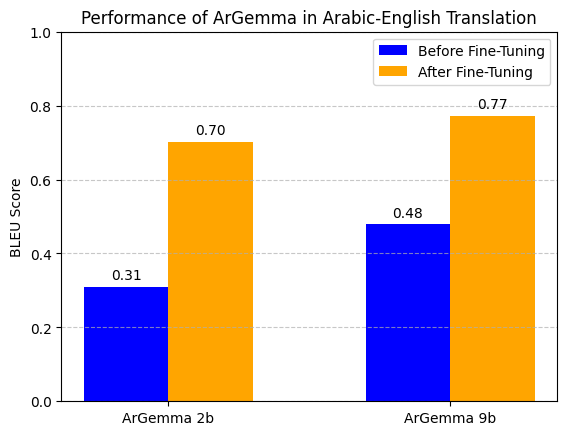

In [34]:
# Example usage of the function:
plot_bleu_scores(
    0.3094, 0.7022,  # BLEU scores for ArGemma 2b
    0.4788, 0.7714   # BLEU scores for ArGemma 9b
)

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note:</strong> ArGemma performs exceptionally well in translation between Arabic and English. However, due to the structural limitations of the BLEU score, the results appear slightly lower than expected.
    </p>
</div>


## 7.2.Summarization ✍️

ROUGE (Recall-Oriented Understudy for Gisting Evaluation) measures the quality of generated text by comparing it to reference texts. It evaluates how well the content of the generated text matches the reference text using the following key metrics:

1. **ROUGE-1:**  
   Measures the overlap of unigrams (individual words) between the generated and reference texts.  
   - **Purpose:** Provides a basic evaluation of content coverage.  
   - **Example:**  
     Reference: "The cat sat on the mat."  
     Generated: "The cat is on the mat."  
     Matching unigrams: "The," "cat," "on," "the," "mat."  

2. **ROUGE-2:**  
   Measures the overlap of bigrams (pairs of consecutive words) between the generated and reference texts.  
   - **Purpose:** Captures the preservation of word sequences and contextual flow.  
   - **Example:**  
     Reference: "The cat sat on the mat."  
     Generated: "The cat is on the mat."  
     Matching bigrams: "The cat," "on the," "the mat."  

3. **ROUGE-L:**  
   Focuses on the longest common subsequence (LCS) between the generated and reference texts.  
   - **Purpose:** Evaluates fluency and the logical ordering of words.  
   - **Example:**  
     Reference: "The cat sat on the mat."  
     Generated: "The mat was sat on by the cat."  
     LCS: "The cat sat on the mat."

### Metrics and Scores
ROUGE scores can be calculated in three ways:  
- **Recall:** Proportion of reference text n-grams that are present in the generated text.  
- **Precision:** Proportion of generated text n-grams that match the reference.  
- **F1-Score:** A harmonic mean of precision and recall.

---

By combining these variants, ROUGE provides a comprehensive evaluation of summarization quality, focusing on both content preservation and coherence.

In [ ]:
def generate_responses(test_prompts, model, max_length=1000):
    """
    Generate model responses for the provided test prompts.

    Args:
        test_prompts (list): List of prompts to be used for generating responses.
        model (object): The model used to generate responses (e.g., gemma_lm).
        max_length (int): The maximum length of the generated response.

    Returns:
        list: List of model responses.
    """
    responses = []

    # Generate responses for each prompt in the test set
    for prompt in test_prompts:
        try:
            # Generate response and extract the part after "Response:"
            response = model.generate(prompt, max_length=max_length).split("Response:")[1].strip()
            responses.append(response)
        except Exception as e:
            # Handle any potential errors (e.g., in case "Response:" is not found)
            print(f"Error processing prompt: {prompt}. Error: {e}")
            responses.append("Error generating response")

    return responses

In [ ]:
# Load LoRA weights to apply fine-tuned weights
gemma_lm.backbone.load_lora_weights("/kaggle/input/argemma/other/default/11/ArGemma_9b_sm.lora.h5")

# Generate responses before fine-tuning 
#gen_res_before = generate_responses(test_instructions_summarization, gemma_lm)

# Generate responses after fine-tuning
gen_res_after = generate_responses(test_instructions_summarization, gemma_lm)

In [ ]:
def rouge_1_score(reference, generated):
    """
    Calculate ROUGE-1 score (Recall, Precision, F1) based on unigram overlap.

    Args:
        reference (str): Reference text.
        generated (str): Generated text.

    Returns:
        dict: ROUGE-1 scores (Recall, Precision, F1).
    """
    # Tokenize texts into words
    ref_tokens = reference.split()
    gen_tokens = generated.split()
    
    # Count unigrams in reference and generated texts
    ref_counts = Counter(ref_tokens)
    gen_counts = Counter(gen_tokens)
    
    # Compute overlap
    overlap = sum((ref_counts & gen_counts).values())  # Intersection counts
    
    # Recall: Overlap count divided by the length of the reference
    recall = overlap / len(ref_tokens) if ref_tokens else 0.0
    # Precision: Overlap count divided by the length of the generated text
    precision = overlap / len(gen_tokens) if gen_tokens else 0.0
    # F1 score: Harmonic mean of precision and recall
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        "Recall": recall,
        "Precision": precision,
        "F1": f1_score,
    }
    
def lcs_length(str1, str2):
    """
    Calculate the length of the Longest Common Subsequence (LCS) between two strings.

    Args:
        str1 (str): First input string.
        str2 (str): Second input string.

    Returns:
        int: Length of the LCS.
    """
    m, n = len(str1), len(str2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if str1[i - 1] == str2[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])

    return dp[m][n]

def rouge_l_score(reference, generated):
    """
    Calculate ROUGE-L score (Recall, Precision, F1) between a reference and a generated text.

    Args:
        reference (str): Reference text.
        generated (str): Generated text.

    Returns:
        dict: ROUGE-L scores (Recall, Precision, F1).
    """
    # Tokenize texts into words
    ref_tokens = reference.split()
    gen_tokens = generated.split()
    
    # Compute LCS
    lcs = lcs_length(ref_tokens, gen_tokens)
    
    # Recall: LCS length divided by the length of the reference
    recall = lcs / len(ref_tokens) if ref_tokens else 0.0
    # Precision: LCS length divided by the length of the generated text
    precision = lcs / len(gen_tokens) if gen_tokens else 0.0
    # F1 score: Harmonic mean of precision and recall
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        "Recall": recall,
        "Precision": precision,
        "F1": f1_score,
    }

def compute_rouge_score(references, generated_texts, rouge_type="rouge-1"):
    """
    Calculate average ROUGE scores for a dataset based on the selected ROUGE type.

    Args:
        references (list): List of reference texts.
        generated_texts (list): List of generated texts.
        rouge_type (str): Type of ROUGE metric to compute, either 'rouge-1' or 'rouge-l'.

    Returns:
        tuple: Average Recall, Precision, and F1 scores across the dataset.
    """
    all_recall = []
    all_precision = []
    all_f1 = []

    for ref, gen in zip(references, generated_texts):
        if rouge_type == "rouge-1":
            scores = rouge_1_score(ref, gen)
        elif rouge_type == "rouge-l":
            scores = rouge_l_score(ref, gen)
        else:
            raise ValueError("Invalid ROUGE type. Choose 'rouge-1' or 'rouge-l'.")

        all_recall.append(scores["Recall"])
        all_precision.append(scores["Precision"])
        all_f1.append(scores["F1"])

    average_recall = np.mean(all_recall)
    average_precision = np.mean(all_precision)
    average_f1 = np.mean(all_f1)

    return average_recall, average_precision, average_f1

In [ ]:
# Calculate ROUGE-1 and ROUGE-L scores before fine-tuning 
# 2b (0.0115, 0.01335, 0.0099) (0.0113, 0.0125, 0.0096)
# 9b (0.0689, 0.1135, 0.0838)  (0.0597, 0.0978, 0.0725)
rouge_score_before = compute_rouge_score(test_texts_summarization, gen_res_before,rouge_type="rouge-l") 

# Calculate ROUGE-1 and ROUGE-L scores after fine-tuning 
# 2b (0.4256, 0.6814, 0.5134) (0.3923, 0.6215, 0.4713)
# 9b (0.3573, 0.6406, 0.4505) (0.3233, 0.5744, 0.4063)
rouge_score_after = compute_rouge_score(test_texts_summarization, gen_res_after,rouge_type="rouge-l") 

In [35]:
def plot_rouge_scores(# ROUGE scores for 2B model before fine-tuning
                      recall_2b_before, precision_2b_before, f1_2b_before,
                      # ROUGE scores for 2B model after fine-tuning
                      recall_2b_after, precision_2b_after, f1_2b_after,
                      # ROUGE scores for 9B model before fine-tuning
                      recall_9b_before, precision_9b_before, f1_9b_before,
                      # ROUGE scores for 9B model after fine-tuning
                      recall_9b_after, precision_9b_after, f1_9b_after,
                      rouge_type = 'rouge-1'):

    # Labels and scores
    recall_before        = [recall_2b_before, recall_9b_before]
    recall_after         = [recall_2b_after,  recall_9b_after]
    
    precision_before     = [precision_2b_before, precision_9b_before]
    precision_after      = [precision_2b_after,  precision_9b_after]
    
    f1_before            = [f1_2b_before, f1_9b_before]
    f1_after             = [f1_2b_after,  f1_9b_after]

    models = ['ArGemma 2b', 'ArGemma 9b']

    x = np.arange(len(models))  # Positions for the bars
    bar_width = 0.05  # Reduced width for better spacing

    # Plotting all metrics in one graph
    fig, ax = plt.subplots(figsize=(10, 6))

    # Plotting ROUGE-1 Recall scores
    ax.bar(x - bar_width, recall_before, width=bar_width, color='#3889f8', label='Recall Before Fine-Tuning')
    ax.bar(x, recall_after, width=bar_width, color='#0000FF', label='Recall After Fine-Tuning')

    # Plotting ROUGE-1 Precision scores
    ax.bar(x + 2*bar_width, precision_before, width=bar_width, color='#FFFF00', label='Precision Before Fine-Tuning')
    ax.bar(x + 3*bar_width, precision_after, width=bar_width, color='#000000', label='Precision After Fine-Tuning')

    # Plotting ROUGE-1 f1_score scores
    ax.bar(x + 5*bar_width, f1_before, width=bar_width, color='#CBC3E3', label='f1_score Before Fine-Tuning')
    ax.bar(x + 6*bar_width, f1_after, width=bar_width, color='#e40078', label='f1_score  After Fine-Tuning')

    # Setting the X-axis labels
    ax.set_xticks(x + 2*bar_width)  # Adjusting the position for the x-axis ticks
    ax.set_xticklabels(models)

    # Adding labels, title, and grid
    ax.set_ylabel('Scores')
    if rouge_type == 'rouge-1':
        ax.set_title(f'ROUGE-1 Performance Before and After Fine-Tuning')
    else:
        ax.set_title(f'ROUGE-L Performance Before and After Fine-Tuning')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Adding the legend in the middle
    ax.legend(loc='center', bbox_to_anchor=(0.5, -0.15), ncol=3)

    # Show the chart
    plt.tight_layout()
    plt.show()

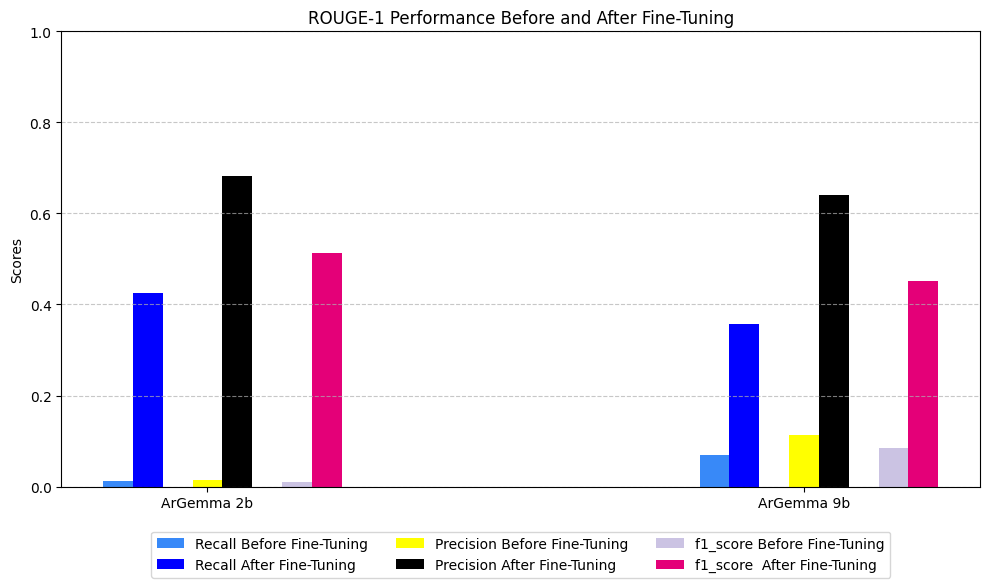

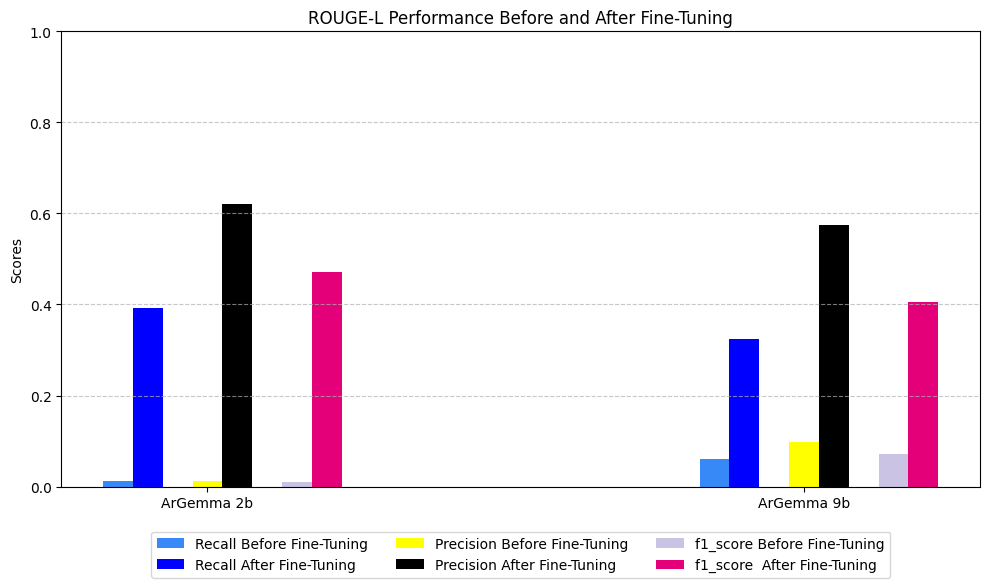

In [36]:
# Give the Rouge-1 scores before and after fine tunig for 2b and 9b models
# 2b (0.0115, 0.01335, 0.0099) | (0.4256, 0.6814, 0.5134) 
# 9b (0.0689, 0.1135, 0.0838) |  (0.3573, 0.6406, 0.4505) 
plot_rouge_scores(0.0115, .01335, 0.0099,   # 2B before fine-tuning 
                  0.4256, 0.6814, 0.5134,   # 2B after fine-tuning 
                  0.0689, 0.1135, 0.0838,   # 9B before fine-tuning
                  0.3573, 0.6406, 0.4505,   # 9B after fine-tuning
                  "rouge-1"                 # rouge type
)    
# Give the Rouge-L  scores before and after fine tunig for 2b and 9b models
# 2b (0.0113, 0.0125, 0.0096) | (0.3923, 0.6215, 0.4713)
# 9b (0.0597, 0.0978, 0.0725) | (0.3233, 0.5744, 0.4063)
plot_rouge_scores(0.0113, 0.0125, 0.0096,   # 2B before fine-tuning 
                  0.3923, 0.6215, 0.4713,   # 2B after fine-tuning 
                  0.0597, 0.0978, 0.0725,   # 9B before fine-tuning
                  0.3233, 0.5744, 0.4063,   # 9B after fine-tuning
                  "rouge-l"                 # rouge type
)

## 7.3.Storytelling | DialogueGen 📖💬

In [37]:
# Load LoRA weights to apply fine-tuned weights
gemma_lm.backbone.load_lora_weights("/kaggle/input/argemma/other/default/11/ArGemma_9b_sd.lora.h5")

# write a story with this title(a smart girl)
print(gemma_lm.generate("Instruction:\nاكتب قصة بهذا العنوان: الطفلة الذكية\n\nResponse:\n", max_length=512))
print("\n-----------------------------------------------------------------------------------\n")
# write a dialogue with this title(The importance of science)
print(gemma_lm.generate("Instruction:\nاكتب حوار بهذا العنوان: أهمية العلم\n\nResponse:\n", max_length=512))
print("\n-----------------------------------------------------------------------------------\n")
# write a message with this title(Request sick leave)
print(gemma_lm.generate("Instruction:\nاكتب رسالة بهذا العنوان: طلب اجازة مرضية\n\nResponse:\n", max_length=512))

Instruction:
اكتب قصة بهذا العنوان: الطفلة الذكية

Response:
في قرية صغيرة، كانت هناك طفلة تُدعى ليلى. كانت ليلى معروفة بذكائها وفضولها. كانت تحب استكشاف العالم من حولها وتعلم أشياء جديدة. في يوم من الأيام، قررت ليلى أن تذهب إلى الغابة القريبة لجمع الأزهار. بينما كانت تتجول في الغابة، وجدت شيئًا غريبًا تحت شجرة كبيرة. كان صندوقًا قديمًا مغطى بالغبار. 

بدأت ليلى تتساءل عما يوجد داخل الصندوق. كانت تشعر بالفضول الشديد. بعد أن حاولت فتحه، وجدت أن الصندوق يحتوي على مجموعة من الكتب القديمة. كانت الكتب مليئة بالقصص والألغاز. قررت ليلى أن تقرأ الكتب وتتعلم منها. 

مع مرور الوقت، أصبحت ليلى أكثر ذكاءً وعلماً. بدأت تساعد أهل قريتها في حل المشكلات اليومية. كانت تستخدم معرفتها في الزراعة، والطب، والفنون. 

أصبح أهل القرية يعتمدون على ليلى في كل شيء. كانت تُعتبر رمزًا للذكاء والإبداع. وعندما كبرت، أصبحت ليلى عالمة مشهورة، لكنها لم تنسَ أبدًا قريتها وأهلها الذين دعموها في رحلتها.

-----------------------------------------------------------------------------------

Instruction:
اكتب حوار بهذا العنوا

In [38]:
def plot_evaluation_results(data, title):
    """
    Plots the evaluation results based on survey responses and ensures numbers fit within the graph.
    
    :param data: Dictionary containing evaluation categories and response counts.
    :param title: The title of the plot (e.g., "Story Evaluation Results" or "Dialogue Evaluation Results").
    """
    categories = list(data.keys())
    yes_values = [data[category]["Yes"] for category in categories]
    no_values = [data[category]["No"] for category in categories]
    some_extent_values = [data[category]["To some extent"] for category in categories]

    # Plotting
    width = 0.2  # width of the bars
    x = range(len(categories))

    fig, ax = plt.subplots(figsize=(10, 6))

    # Custom colors for each response
    yes_bars = ax.bar(x, yes_values, width, label='Yes', color='#2196F3')  # Blue
    no_bars = ax.bar([p + width for p in x], no_values, width, label='No', color='#FFEB3B')  # Yellow
    some_extent_bars = ax.bar([p + 2 * width for p in x], some_extent_values, width, label='To some extent', color='#795548')  # Brown

    # Adding numbers on top of bars
    for bars in [yes_bars, no_bars, some_extent_bars]:
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2, 
                height - (0.05 * max(yes_values + no_values + some_extent_values)) if height > ax.get_ylim()[1] * 0.9 else height + 0.1, 
                f'{int(height)}', 
                ha='center', 
                va='bottom', 
                color='black'
            )

    # Adjust y-axis to fit all numbers
    max_value = max(yes_values + no_values + some_extent_values)
    ax.set_ylim(0, max_value * 1.1)

    ax.set_xlabel('Criteria')
    ax.set_ylabel('Number of Responses')
    ax.set_title(title)
    ax.set_xticks([p + width for p in x])
    ax.set_xticklabels(categories)
    ax.legend()

    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

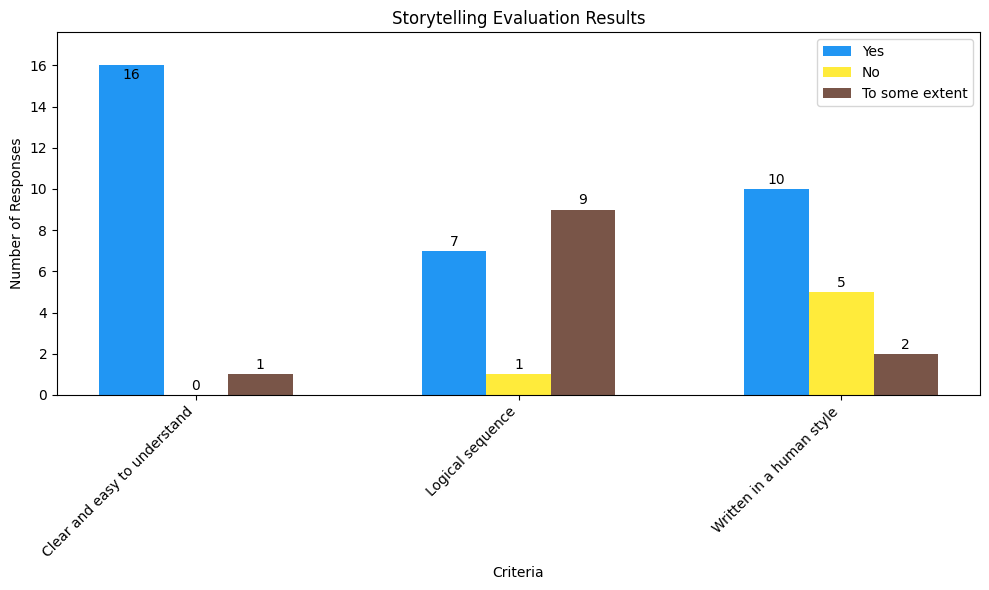

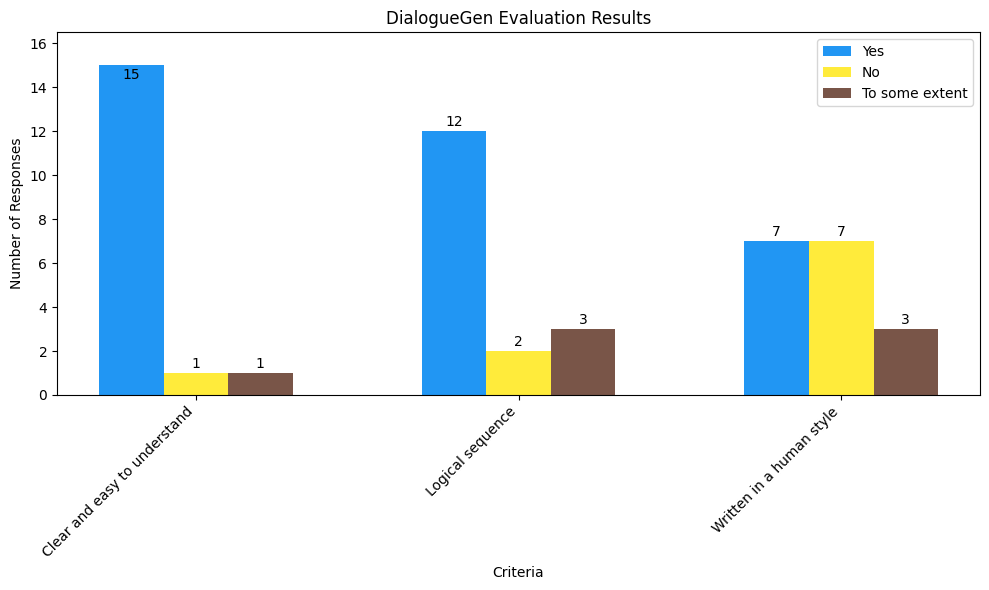

In [39]:
# Storytelling evaluation
story_data = {
    "Clear and easy to understand": {"Yes": 16, "No": 0, "To some extent": 1},
    "Logical sequence": {"Yes": 7, "No": 1, "To some extent": 9},
    "Written in a human style": {"Yes": 10, "No": 5, "To some extent": 2}
}

# DialogueGen evaluation
dialogue_data = {
    "Clear and easy to understand": {"Yes": 15, "No": 1, "To some extent": 1},
    "Logical sequence": {"Yes": 12, "No": 2, "To some extent": 3},
    "Written in a human style": {"Yes": 7, "No": 7, "To some extent": 3}
}

# Plot the results for Storytelling and DialogueGen
plot_evaluation_results(story_data, "Storytelling Evaluation Results")
print()
plot_evaluation_results(dialogue_data, "DialogueGen Evaluation Results")

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note:</strong> In this task, the model was evaluated by native Arabic speakers. One story and one dialogue were generated by the model and presented to them for evaluation. The goal was to understand how people perceive and think when reading a story or dialogue generated by ArGemma model.
    </p>
</div>

## 7.4.Classical vs. Modern Arabic 🌉

In [40]:
# Define a function to ask a query and get a response from the model
def ask_query(query):
    '''
    Given a query, gather appropriate context and pass both into the model
    to get a response

    Parameters:
    query (str): question to ask the model

    Returns:
    response (str): response from the model
    '''
    # Encode the query
    question_embedding = bi_encoder.encode(query, convert_to_tensor=True)
    
    # Perform semantic search to get relevant context
    hits = util.semantic_search(question_embedding, semantic_search_model, top_k=3)
    hits = hits[0]
    
    # Build the context from the retrieved hits
    context = " "
    for hit in hits:
        context += RAG_knowledge_base[hit['corpus_id']] + "\n\n"
    
    # Add separator and the query instruction
    context += "-------------------------------------------------------------------------\n"
    context += f"Instruction: {query}\nResponse:\n"
    #print(context)
    # Feed the context into the Gemma model and generate a response
    response = gemma_lm.generate(context, max_length=512)
    
    # Print the response after the "Response:" tag
    return response.split("Response:")[1]

In [41]:
# Load LoRA weights to apply fine-tuned weights
gemma_lm.backbone.load_lora_weights("/kaggle/input/argemma/other/default/11/ArGemma_9b_br.lora.h5")
# write a story with this title(a smart girl)

# Explain this Quranic verse...
print(ask_query("فسر هذه الاية القرانية: : مايلفظ من قول الا لديه رقيب عتيد"))
print("\n----------------------\n")

# Explain this Arabic proverb...
print(ask_query("اشرح هذا المثل العربي: من جد وجد ومن زرع حصد"))
print("\n----------------------\n")

# Meaning of the word...
print(ask_query("معنى كلمة: زنيم"))
print("\n----------------------\n")

# Explain this poem...
print(ask_query("اشرح هذا البيت الشعري: بِالحَزم وَالعَزم وَالأفكار وَالحِكَمِ***تَنالُ من لَم يُنَل بِالسَيف وَالقَلمِ"))


ما يقول من قول إلا لديه ملك رقيب على ما يقوله حاضر.

----------------------


هذا المثل يعبر عن أهمية العمل الجاد والاجتهاد. يعني أن الشخص الذي يبذل جهداً في سعيه نحو أهدافه سيحقق النجاح في النهاية، مثلما أن من يزرع بذوراً سيحصد ثمارها لاحقاً. يشجع هذا المثل على المثابرة والإصرار لتحقيق النتائج المرجوة.

----------------------


زَنِيم١ [مفرد]: ج زنيمون وزُنَماءُ: صفة مشبَّهة تدلّ على الثبوت من زنُمَ: لئيم له علامة من علامات الشَّرِّ تُميِّزه.

----------------------


يصف الشاعر كيف يمكن أن تصل الأهداف التي لا يمكن الوصول إليها بالسيف والقلم.


In [42]:
def plot_evaluation_graph(criteria, scores):
    """
    Plots a bar chart for system evaluation based on given criteria and scores.

    Parameters:
        criteria (list of str): The evaluation criteria.
        scores (list of float): The scores for each criterion (out of 10).
    """
    # Create a bar chart
    plt.figure(figsize=(12, 6))  # Increased width for better spacing of labels
    bars = plt.bar(criteria, scores, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])

    # Add value labels on top of the bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2 - 0.1, yval + 0.2, f"{yval:.1f}", fontsize=12)

    # Chart customization
    plt.title("Bridging Classical and Modern Arabic", fontsize=16)
    plt.ylabel("Score", fontsize=12)
    plt.xlabel("Criteria", fontsize=12)
    plt.ylim(0, 10)
    plt.xticks(rotation=20, ha='right', fontsize=10)  # Rotates labels for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Show the graph
    plt.tight_layout()
    plt.show()

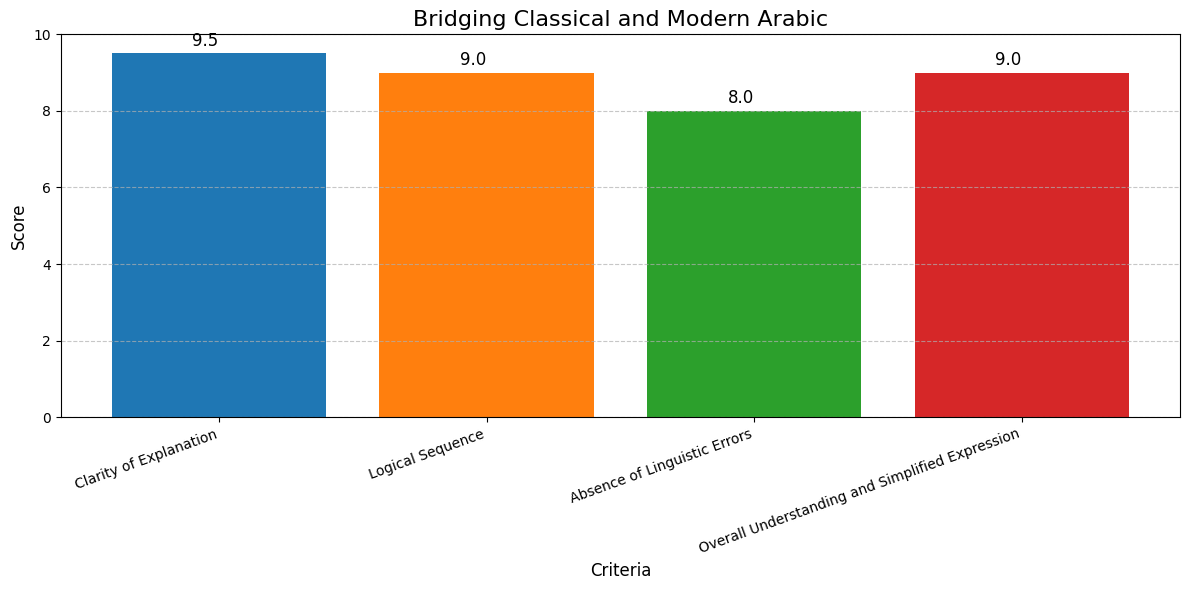

In [43]:
criteria = [
    "Clarity of Explanation",
    "Logical Sequence",
    "Absence of Linguistic Errors",
    "Overall Understanding and Simplified Expression"
]

scores = [9.5, 9.0, 8.0, 9.0] 
plot_evaluation_graph(criteria, scores)

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note:</strong> In this task, the model was evaluated by two Arabic language experts who assessed its outputs. While the results were generally good, the accuracy of the 2B model was slightly lower than the 9B model, highlighting the need for additional training. The fine-tuning process for bridging Classical and Modern Arabic combined Supervised Fine-Tuning, Retrieval-Augmented Generation (RAG), and Few-Shot Prompting to enhance contextual understanding and accuracy. The performance was influenced by three key factors: the quality of the data, the effectiveness of fine-tuning strategies, and the performance of the semantic search model. High-quality, well-structured instruction-response data was essential for achieving good results, while RAG-based retrieval and optimized prompting techniques played a significant role in improving contextual relevance. Although the custom Arabic semantic search model effectively retrieved relevant information, occasional retrieval errors affected output accuracy. Further enhancements in data quality, search model optimization, and continued fine-tuning can collectively improve overall performance.
    </p>
</div>

# 8.Let's try ArGemma

In [ ]:
def prepare_RAG_knowledge_base(file_paths):
    """
    Prepare a Knowledge Base for Retrieval-Augmented Generation (RAG) from multiple datasets.

    Args:
        file_paths (dict): Dictionary with keys representing dataset names and values as file paths.

    Returns:
        list: List of formatted knowledge base entries for RAG.
    """
    # Read all datasets
    df1 = pd.read_csv(file_paths["quran_with_tafsir"])
    df2 = pd.read_csv(file_paths["classical_proverbs"])
    df3 = pd.read_csv(file_paths["colloquial_proverbs"])
    df4 = pd.read_csv(file_paths["popular_proverbs"])
    df5 = pd.read_csv(file_paths["arabic_lexicon"])
    df6 = pd.read_csv(file_paths["arabic_poetry"])

    knowledge_base = []
    
    # Quran with Tafsir
    for _, row in df1.iterrows():
        knowledge_base.append(f"فسر هذه الآية القرآنية: {row['ayah_ar']}\n{row['tafsir']}")

    # Classical Arabic Proverbs
    for _, row in df2.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي الفصيح: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Colloquial Arabic Proverbs
    for _, row in df3.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي العامي: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Popular Arabic Proverbs
    for _, row in df4.iterrows():
        knowledge_base.append(f"اشرح هذا المثل العربي: {row['Arabic Proverb']}\n{row['Explanation']}")

    # Arabic Lexicon
    for _, row in df5.iterrows():
        knowledge_base.append(f"معاني الكلمات في الجذر: {row['root']}\n{row['words_meanings']}")

    # Arabic Poetry
    for _, row in df6.iterrows():
        # Explain the poetry line
        knowledge_base.append(f"اشرح هذا البيت الشعري: {row['line']}\n{row['explanation_arabic']}")
        # Provide poetry with explanation
        knowledge_base.append(f"اكتب بيت من الشعر العربي مع الشرح:\nالبيت الشعري: {row['line']}\nالشرح: {row['explanation_arabic']}")

    return knowledge_base

In [ ]:
file_paths = {
    "quran_with_tafsir": "/kaggle/input/quran-with-tafsir/Quran with tafsir.csv",
    "classical_proverbs": "/kaggle/input/arabic-proverbs-collection/classical_arabic_proverbs.csv",
    "colloquial_proverbs": "/kaggle/input/arabic-proverbs-collection/colloquial_arabic_proverbs.csv",
    "popular_proverbs": "/kaggle/input/arabic-proverbs-collection/popular_arabic_proverbs.csv",
    "arabic_lexicon": "/kaggle/input/arabic-lexicons/lexicon_of_the_modern_arabic_language.csv",
    "arabic_poetry": "/kaggle/input/arabic-poetry-verses-and-explanations/verse_explained.csv"
}
RAG_knowledge_base = prepare_RAG_knowledge_base(file_paths)

In [ ]:
def start_demo(model, version):
    
    global current_variant  
    messages = []
    variants = ["Translation", "Summarization", "Storytelling & DialogueGen", "Classical vs Modern Arabic"]
    current_variant = variants[0]  
    
    # Dropdown for variant selection
    variant_dropdown = Dropdown(
        options=variants,
        value=variants[0],
        description='TASK:',
        layout=Layout(width='300px')
    )

    # Chat field and button
    chat_field = Textarea(
        placeholder='اكتب هنا',
        disabled=False,
        layout=Layout(width='80%'),
    )
    chat_field.add_class('chat-field')

    submit_btn = Button(
        layout=Layout(width='15%'),
        description="Submit",
        button_style="info",
    )

    # Layouts
    input_area = HBox([chat_field, Box(layout=Layout(width='15px', height="80px")), submit_btn], layout=Layout(align_items='center'))
    chat_messages = VBox(messages)
    chat_messages.add_class('chat-messages')

    chat = VBox([variant_dropdown, chat_messages, input_area], layout=Layout(width='600px', height='600px'))

    # CSS Styling
    style = """
    <style>
    .agent-msg {
        background-color:#ffc880;
        padding: 8px 8px 8px 8px;
        border-radius: 8px;
        max-width: 500px;
        white-space: normal;
        display: block;
        align-self: flex-start;
        margin: 0px;
    }

    .user-msg {
        background-color:#abe4ff;
        padding: 8px 8px 8px 8px;
        border-radius: 8px;
        max-width: 500px;
        white-space: normal;
        display: block;
        align-self: flex-end;
        margin: 0px;
    }

    .chat-field textarea {
        border-radius: 8px;
    }

    .chat-messages {
        overflow: auto;
        margin-top: auto;
        max-height: 500px;
    }

    .widget-vbox {
        border: 2px solid #cccccc; 
        border-radius: 8px;       
        padding: 8px;            
        background-color: #f9f9f9; 
    }
    </style>
    """
    
    # Function to handle dropdown change
    def on_variant_change(change):
        global current_variant  
        current_variant = change['new']

    variant_dropdown.observe(on_variant_change, names='value')

    # Submit function
    def submit(_):
        prompt = chat_field.value
        chat_field.value = ""

        user_msg = HTML(f"""
        <div style="display: flex; flex-direction: row-reverse; margin: 2px;"> 
            <div class="user-msg">{prompt}<div>
        <div>
        """)

        agent_msg = HTML(f"""
        <div style="display: flex; margin: 2px;"> 
            <div class="agent-msg">...<div>
        </div>
        """)

        messages.extend([user_msg, agent_msg])
        chat_messages.children = messages

        # Generate response based on variant


        if current_variant == "Translation":
            gemma_lm.backbone.load_lora_weights(f"/kaggle/input/argemma/other/default/11/{version}_tr.lora.h5")
            answer = model.generate(f"Instruction:\n{prompt}\n\nResponse:\n", max_length=512)
            answer = answer.split("Response:")[1]
            #answer = "tr"
        elif current_variant == "Summarization":
            gemma_lm.backbone.load_lora_weights(f"/kaggle/input/argemma/other/default/11/{version}_sm.lora.h5")
            answer = model.generate(f"Instruction:\n{prompt}\n\nResponse:\n", max_length=512)
            answer = answer.split("Response:")[1]
            #answer = "sm"
        elif current_variant == "Storytelling & DialogueGen":
            gemma_lm.backbone.load_lora_weights(f"/kaggle/input/argemma/other/default/11/{version}_sd.lora.h5")
            answer = model.generate(f"Instruction:\n{prompt}\n\nResponse:\n", max_length=512)
            answer = answer.split("Response:")[1]
            #answer = "sd"
        elif current_variant == "Classical vs Modern Arabic":
            gemma_lm.backbone.load_lora_weights(f"/kaggle/input/argemma/other/default/11/{version}_br.lora.h5")
            # Encode the query
            question_embedding = bi_encoder.encode(prompt, convert_to_tensor=True)
            # Perform semantic search to get relevant context
            hits = util.semantic_search(question_embedding, semantic_search_model, top_k=3)
            hits = hits[0]
            # Build the context from the retrieved hits
            context = " "
            for hit in hits:
                context += RAG_knowledge_base[hit['corpus_id']] + "\n\n" 
            # Add separator and the query instruction
            context += "-------------------------------------------------------------------------\n"
            context += f"Instruction: {prompt}\nResponse:\n"

            # Feed the context into the Gemma model and generate a response
            answer = gemma_lm.generate(context, max_length=512)
            answer = answer.split("Response:")[1]

        else:
            answer = "error"

        agent_msg = HTML(f"""
        <div style="display: flex; margin: 2px;"> 
            <div class="agent-msg">{answer}<div>
        </div>
        """)
        messages[-1] = agent_msg
        chat_messages.children = messages

    submit_btn.on_click(submit)

    # Display chat interface
    display(HTML(style), chat)

In [ ]:
start_demo(gemma_lm, version="ArGemma_9b")

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note:</strong> To chat with ArGemma, you need to run the notebook. Additionally, don't forget to prepare the RAG_knowledge_base using the cell above and set up the environment from the Environment Setup section.
    </p>
</div>

# 9.What's Next?

* **Data**:
  - *Translation*: Focus on collecting long Arabic-English pairs, especially from short stories and dialogues. Consider adding more languages to expand the translation capabilities of ArGemma.
  - *Storytelling*: Gather more diverse types of Arabic stories. Fine-tune the model for specific genres, such as romantic, religious, and folkloric stories.
  - *Summarization*: Expand the range of texts for summarization, including stories, dialogues, historical texts, academic articles, lectures, and texts in both Classical and Modern Arabic.
  - *Classical and Modern Arabic*: Bridge the gap between Classical and Modern Arabic by collecting bilingual texts, classical works with modern commentaries, and parallel corpora. Additionally, use lexicons that cover both forms of Arabic
* **Fine-Tuning**: Use more complex fine-tuning techniques to improve the model’s performance, especially in context-based tasks.
* **Evaluation**: Incorporate diverse evaluation metrics like LEMMA-ROUGE to assess the quality of the generated summaries, especially for Arabic abstractive text summarization.

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        <strong>Note:</strong> This notebook is designed to encourage you to use Gemma and fine-tune it for your language. Starting with an easy-to-follow and straightforward approach can help you avoid feeling overwhelmed or bored right from the start. I’ve kept it simple and concise, avoiding overly complicated methods or lengthy explanations. In the second version of this notebook, I plan to introduce more advanced features, such as integrating Gemma with LangChain and Quantization techniques, along with other enhancements.
    </p>
</div>

<div style="border: 1px solid #ccc; padding: 30px; max-width: 900px; margin: 30px auto; background-color: #fdfdfd; box-shadow: 0px 5px 15px rgba(0, 0, 0, 0.05); font-family: 'Georgia', serif; line-height: 1.8;">
    <p style="font-size: 120%; color: #333;">
        Thank you for taking the time to go through this notebook. I hope it was informative and helpful. A special thanks to the Kaggle community for sharing their invaluable knowledge and resources. Your generosity and collaboration make learning and growing as a data scientist truly rewarding. Feel free to leave your thoughts, suggestions, or feedback in the comments. Let’s keep sharing ideas and inspiring each other!
    </p>
</div>



# 10.Resources
1. **Gemma Documentation**:
   - [Gemma Docs](https://ai.google.dev/gemma/docs) : Comprehensive guide to understanding and using Gemma for AI development.
2. **Gemma Developer Day Playlists**:
   - [Gemma Developer Day 2024](https://www.youtube.com/playlist?list=PLOU2XLYxmsIL8TxLOcsVI_hCq0c6cO-WQ)
   - [Gemma Developer Day Tokyo](https://www.youtube.com/playlist?list=PLOU2XLYxmsIKOyXflnuPK-qe32hZLc2HB)
3. **Google – AI Assistants for Data Tasks with Gemma**:
   - [Competition Overview](https://www.kaggle.com/competitions/data-assistants-with-gemma/overview)
4. **GemmAr: Enhancing LLMs Through Arabic Instruction-Tuning**:
   - [Research Paper](https://arxiv.org/pdf/2407.02147) :  The paper presents InstAr-500k, a comprehensive Arabic instruction dataset, and introduces GemmAr-7B-V1, a fine-tuned model that significantly improves performance on Arabic NLP tasks, bridging the gap between English and Arabic language models.
5. **Building a Custom Arabic Semantic Search Model**:
   - [Read the article](https://huggingface.co/blog/Omartificial-Intelligence-Space/building-custom-arabic-semantic-search-model)
6. **Shamela Library**:
    - [Shamela Library](https://shamela.ws/) : A digital library platform with a vast collection of Arabic books, especially in Islamic studies and Arabic literature.